In [ ]:
pip install umap-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.8/88.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.9/56.9 kB 3.0 MB/s eta 0:00:00


In [ ]:
import re
import pandas as pd
import numpy as np
from collections import OrderedDict
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from umap import UMAP

In [ ]:
# Load data

from google.colab import files
uploaded = files.upload()

Saving comments_translated.csv to comments_translated.csv


In [ ]:
df = pd.read_csv('comments_translated.csv')
df

,comments,cleaned_comments,translated_comments
0,ras,rien à signaler,nothing to report
1,produit en rupture cmm = 65,produit en rupture de stock cmm 65,product out of stock cmm 65
2,cmm=50,cmm 50,cmm 50
3,cmm=1,cmm 1,cmm 1
4,cmm=21,cmm 21,cmm 21
...,...,...,...
1915,consommation mensuelle est 100,consommation mensuelle est 100,monthly consumption is 100
1916,ras / nous avons compté en unité mais pas en b...,rien à signaler / nous avons compté en unité m...,nothing to report / we counted in units but no...
1917,service ferme,service fermé,closed service
1918,activite arretee,activité arrêtée,activity stopped


In [ ]:
# Update numeric-only observations
def update_numeric_observations(comment):
    comment_str = str(comment)  # Convert to string
    if comment_str.isdigit():
        return f'ordered qty {comment_str}'
    return comment_str

df['translated_comments'] = df['translated_comments'].apply(update_numeric_observations)

# Function to update the equations
def update_equations(equation):
    if re.match(r'^\(?\d+\*\d+\)?.*$', equation) and '=' not in equation:
        return f"equation - {equation}"
    return equation

# Apply the function to the column
df['translated_comments'] = df['translated_comments'].apply(update_equations)

df

,comments,cleaned_comments,translated_comments
0,ras,rien à signaler,nothing to report
1,produit en rupture cmm = 65,produit en rupture de stock cmm 65,product out of stock cmm 65
2,cmm=50,cmm 50,cmm 50
3,cmm=1,cmm 1,cmm 1
4,cmm=21,cmm 21,cmm 21
...,...,...,...
1915,consommation mensuelle est 100,consommation mensuelle est 100,monthly consumption is 100
1916,ras / nous avons compté en unité mais pas en b...,rien à signaler / nous avons compté en unité m...,nothing to report / we counted in units but no...
1917,service ferme,service fermé,closed service
1918,activite arretee,activité arrêtée,activity stopped


In [ ]:
# Define standard sentences for each scenario.
standard_sentences = {
    "Calculated Expression Adjustment": "calculated_expression_adjustment",
    "Real CMM Adjustment": "real_cmm_adjustment",
    "CMM Reporting in Packaging Units": "cmm_reporting_in_packaging_units",
    "Conversion Error": "conversion_error",
    "Low Demand": "low_demand",
    "Low Turnover": "low_turnover",
    "Sufficient Stock": "sufficient_stock",
    "Insufficient Stock": "insufficient_stock",
    "Overstock": "overstock",
    "Dormant Stock": "dormant_stock",
    "Expiring Stock": "expiring_stock",
    "Shortage Avoidance": "shortage_avoidance",
    "Positive Inventory Fix": "positive_inventory_fix",
    "Negative Inventory Fix": "negative_inventory_fix",
    "Stock Conversion": "stock_conversion",
    "Order Adjustment": "order_adjustment",
    "Delivery Mismatch": "delivery_issues",
    "Rounding Issue": "rounding_issue",
    "Out of Stock": "out_of_stock",
    "High Stock": "high_stock",
    "Revalued Stock": "revalued_stock",
    "Safety Stock": "safety_stock",
    "Urgent Need": "urgent_need",
    "Availability Period Consideration": "availability_period_consideration",
    "Order Not Delivered": "order_not_delivered",
    "Breakup Timeline": "breakup_timeline",
    "Long Breakup": "long_breakup",
    "Prolonged Breakup": "prolonged_breakup",
    "Avoid Breakup": "avoid_breakup",
    "Frequent Breakup": "frequent_breakup",
    "Pre-Breakup": "pre_breakup",
    "Specific Break Period": "specific_break_period",
    "Long-Term Breakup": "long_term_breakup",
    "Immediate Breakup": "immediate_breakup",
    "Normal Consumption": "normal_consumption",
    "High Consumption": "high_consumption",
    "Low Consumption": "low_consumption",
    "Atypical Consumption": "atypical_consumption",
    "Demand Patterns": "demand_patterns",
    "Demand Adjustment": "demand_adjustment",
    "Non-Compliant CMM": "non_compliant_cmm",
    "Incorrect CMM": "incorrect_cmm",
    "CMM Related Events": "cmm_related_events",
    "Staff Request": "staff_request",
    "Risk of Rupture": "risk_of_rupture",
    "Facility Issues": "facility_issues",
    "Transfer In": "transfer_in",
    "Transfer Out": "transfer_out",
    "New Product": "new_product",
    "Reorder Issues": "reorder_issues",
    "Nothing to Report": "nothing_to_report",
    "Pricing Issues": "pricing_issues",
    "Training/Staff Competency": "training_staff_competency",
    'Holiday Season': 'holiday_season'
}


# Map scenarios to their corresponding regex keyword lists.
scenario_patterns = [
    ("Out of Stock", [
        r"out of stock", r"currently out of stock", r"product is out of stock",
        r"out of stock products", r"backordered stock", r"backlogged stock", r"shortage",
        r"prayer help us to overcome shortages", r"quantity insufficient", r"insufficient quantity",
        r"not in stock"
    ]),
    ("Calculated Expression Adjustment", [
        r"ordered qty", r"equation", r"formula", r"calculation", r"double", r"msd",
        r"2 months", r"2 month", r"2xqac", r"two months", r"4 months of ordered stock",
        r"bimonthly", r"order for", r"order\*2", r"method of averages"
    ]),
    ("Real CMM Adjustment", [
        r"actual CMM", r"cmm", r"real CMM", r"correct CMM", r"calculated CMM", r"modified CMM",
        r"CMM is\s*[=:]?[-+*/\.\d]+", r"need CMM is", r"estimated CMM is",
        r"CMM is\s*\d+(?:\.\d+)?", r"actual CMM is\s*[=:]?[-+*/\.\d]+", r"correct CMM is\s*[=:]?[-+*/\.\d]+",
        r"because.*?CMM is", r"CMM is", r"nothing to report CMM is", r"CMM is consistent",
        r"CMM is constant", r"recalculated CMM is", r"updated CMM is", r"revalued CMM is",
        r"adjusted CMM is", r"CMM is adjusted", r"real CMM is", r"CMM is \d+", r"CMM is = \d+",
        r"CMM is \+\d+", r"CMM is : \d+", r"calculated CMM", r"CMM is calculated",
        r"because the real CMM is", r"with CMM", r"CMM is .* and max = \d+ months",
        r"CMM is .* box packaging/.* units", r"cm$", r"cnm=$", r"comm correct=$", r"estimated",
        r"estimates", r"monthly consumption", r"c!mm", r"cnm"
    ]),
    ("CMM Reporting in Packaging Units", [
        r"CMM is \d+ boxes?", r"CMM is \d+ box(?:es)? of .*?", r"CMM is .*? expressed in terms of .*?",
        r"packaging", r"box of", r"pack of", r"expressed in terms of box", r"capacity of .* per box",
        r"adjustment to bring in box", r"alignment to packaging", r"boxes of", r"bts of",
        r"bulbs", r"b/", r"cycles", r"units", r"^\d+box/\d+$", r"^\d+boxes/\d+$", r"^\d+b/\d+$",
        r"a ite is box",r"quantity expressed", r"box the quantities", r"ampoules",
        r"\d+\s*box/\d+\+?\s*\d*", r"1 box/10 implants", r"in cycle", r"per cycle"
    ]),
    ("Conversion Error", [
        r"conversion .*? box into .*?", r"conversion .*? unit into .*?",
        r"adjustment to bring in box .*?", r"conversion", r"converted to box", r"converted to cycle",
        r"adjustment corresponding to the change of unit", r"confusion", r"error",
        r"consumption is in unit and order in box",
        r"month of Oct 10 boxes received and 12 boxes released instead of 0 received and 2 boxes released",
        r"order was placed in unit and not in box",
        r"conversion .*? box into .*?",
        r"conversion .*? unit into .*?",
        r"adjustment to bring in box .*?",
        r"conversion",
        r"converted to box",
        r"converted to cycle",
        r"adjustment corresponding to the change of unit",
        r"confusion",
        r"error",
        r"consumption is in unit and order in box",
        r"consumption is in unit and ordered in box"
    ]),
    ("Low Demand", [
        r"sufficient stock(?:.*?low demand)?", r"slow moving stock", r"stock does not come out",
        r"very sufficient stock because the product does not come out"
    ]),
    ("Low Turnover", [
        r"low turnover product", r"low turnover stock", r"method not used", r"product does not sell well",
        r"low product turnover", r"low recovery rate", r"low turnover rate"
    ]),
    ("Sufficient Stock", [
        r"sufficient stock", r"sufficient stock available", r"sufficient stock to cover one month",
        r"sufficient stock for this month", r"remaining stock, sufficient", r"perfect stock",
        r"controlled stock", r"normal stock", r"predictable stock", r"average stock",
        r"initial stock", r"available", r"stock that can cover", r"store well", r"stored product",
        r"sufficient", r"surstock", r"we have"
    ]),
    ("Insufficient Stock", [
        r"insufficient stock", r"understock", r"soustock", r"no stock", r"stock 0",
        r"completely out of stock", r"stock at zero", r"0 in stock", r"insufficient"
    ]),
    ("Overstock", [
        r"overstock", r"high current stock", r"we are overstocked", r"overstock because expiry close",
        r"latency stock", r"maximum order stock"
    ]),
    ("Dormant Stock", [
        r"dormant stock", r"stock difficult to use", r"requires transfer", r"dormant product", r"mormant product"
    ]),
    ("Expiring Stock", [
        r"stock nearing expiration", r"stock expires", r"stock expires next month",
        r"stock expires in February 2019", r"\d+ boxes expired", r"stock expired", r"expired box",
        r"CMM is expiry date close", r"CMM is stock at expiration", r"expired", r"expires",
        r"expiry", r"expiration"
    ]),
    ("Shortage Avoidance", [
        r"avoid a shortage due to the npspci inventory", r"restocking after shortage"
    ]),
    ("Positive Inventory Fix", [
        r"positive inventory fix", r"positive inventory correction", r"inventory", r"positive inventory"
    ]),
    ("Negative Inventory Fix", [
        r"negative inventory fix"
    ]),
    ("Stock Conversion", [
        r"transformation of stock in box into tablet", r"conversion of tablet stock into cycle",
        r"conversion of stock", r"transformation of stock", r"stock expressed in terms of",
        r"reordered was passed in unit and not in box", r"conditioning", r"unpacked in blister packs"
    ]),
    ("Order Adjustment", [
        r"order .*? adjusted", r"adjustment .*? to match .*?", r"round up .*? to .*?",
        r"rounded", r"rounded up", r"adjust", r"adjustment", r"additional",
        r"normal resumption", r"reduction in the quantity", r"replenishment",
        r"resumption", r"account long break", r"compensate", r"waiting time",
        r"ordered p/\d+",  r"ordered necessary", r"ordered normal",  r"ordered multiplied by 2", r"ordered bi-monthly",
        r"ordered not satisfied", r"order of as\d+"
    ]),
    ("Rounding Issue", [
        r"rounding .*? to .*?", r"rounded up .*?", r"rounded .*? terms of .*?",
        r"rounded", r"rounding", r"round up"
    ]),
    ("High Stock", [
        r"high stock", r"stock max", r"reach max stock", r"stock reinforcement",
        r"max", r"maximum", r"no need"
    ]),
    ("Revalued Stock", [
        r"revalued stock", r"stock revalued", r"inventory correction due to change of counting unit", r"stock revaluation", r"3-cycle box"
    ]),
    ("Safety Stock", [
        r"safety stock", r"no more safety stock", r"remains less than"
    ]),
    ("Urgent Need", [
        r"urgent", r"urgent need", r"on urgent order", r"CMM is .*? urgent need",
        r"prioritize urgent action", r"necessary stock", r"requested", r"quantity ordered",
        r"quantity needed", r"availability essential", r"no delivery possible",
        r"rush order", r"order multiplied by 2", r"important need", r"for needs",
        r"next delivery very far away", r"no book", r"no delivery", r"order required",
        r"product requires", r"stock required", r"waiting period \d+ days", r"ordered in progress"
    ]),
    ("Availability Period Consideration", [
        r"taking into account the availability period", r"availability period needs consideration",
        r"to take into account the CMM .*? availability period", r"taking into account .*? availability",
        r"availability period"
    ]),
    ("Order Not Delivered", [
        r"order not delivered", r"to be delivered", r"delivered", r"delivery of .* boxes",
        r"waiting for delivery", r"awaiting delivery", r"not deliver", r"always ask",
        r"delivery time", r"too far", r"distant", r"fed up with this product",
        r"never deliver", r"never delivers", r"never received", r"never ordered",
        r"never received", r"not deliver", r"delivery district",  r"ordered arrived in February", r"next delivery date", r"remote delivery",
        r"no product releases", r"maternity hospital"
    ]),
    ("Breakup Timeline", [
        r"broken up \d+ months ago", r"broken up \d+ days ago", r"breakup since the beginning of \d{4}",
        r"broken for \d+ days", r"broken up for months", r"broken up for several months", r"broken"
    ]),
    ("Long Breakup", [
        r"long breakup", r"long breakup period", r"long breakup.*?", r"long break CMM is",
        r"CMM is influenced by rupture", r"take into account the CMM is before the break",
        r"old break CMM", r"missing quantity"
    ]),
    ("Prolonged Breakup", [
        r"prolonged breakup", r"broken for more than \d+ days", r"broken for over \d+ days",
        r"too long breakup", r"books since", r"breakup"
    ]),
    ("Avoid Breakup", [
        r"avoid a breakup", r"to avoid breakup", r"avoid breakup", r"avoid breakage"
    ]),
    ("Frequent Breakup", [
        r"frequent breakup"
    ]),
    ("Pre-Breakup", [
        r"pre breakup ds", r"almost breaking up", r"no release for this product",
        r"unmanaged product", r"last order", r"process of breaking", r"before the long break",
        r"slow exit"
    ]),
    ("Specific Break Period", [
        r"breakup 31 days", r"breakup 30 days", r"30 day break", r"broken up 6 months ago",
        r"broken up for 120 days", r"days of breakup", r"breakup", r"break",
        r"break \d+ months$", r"break \d+ days$", r"breakup", r"breakup \d+ months$",
        r"breakup after \d+ months$", r"breakup in ds$", r"breakup of more than \d+ months$",
        r"breakup since (?:[a-zA-Z]+ \d{4})$", r"breakup since the beginning of \d{4}$",
        r"broken for \d+ days$", r"broken for more than \d+ days$", r"broken loan$",
        r"broken more than \d+ months$", r"broken up \d+ months ago$", r"broken up for a long time$",
        r"broken up for over a month$", r"breakup 31 days", r"breakup 30 days", r"30 day break",
        r"broken up 6 months ago", r"broken up for 120 days", r"days of breakup",
        r"exp very proc", r"received on", r"received 1 on", r"recent delivery"
    ]),
    ("Long-Term Breakup", [
        r"long-term breakup", r"breakup of more than \d+ months", r"not holding"
    ]),
    ("Immediate Breakup", [
        r"breakup as of today", r"breakup near", r"break consummated in December",
        r"not use", r"activity stopped", r"0 boxes", r"0 output", r"no request",
        r"no comments", r"no consumption", r"no exit", r"no release of product",
        r"no request", r"not applicable", r"not available", r"not managed",
        r"not precise enough", r"not usable", r"not very useful", r"order arrives",
        r"order date", r"order in", r"order quantity=0", r"price", r"latency",
        r"produces a slow", r"breakage", r"product dispensed", r"product served",
        r"difficult to cover", r"not coming out", r"products not specified", r"rare exit",
        r"remainder", r"unreceived", r"review the unit price", r"waiting for"
    ]),
    ("Normal Consumption", [
        r"normal consumption", r"consumption of the period", r"monthly consumption is \d+",
        r"reported value", r"activity report", r"reports", r"reporting", r"order report",
        r"average rotation", r"good rotation", r"report", r"normal order", r"boxes"
    ]),
    ("High Consumption", [
        r"high demand", r"product in high demand", r"high consumption", r"high consumption product",
        r"demand is strong", r"strong demand", r"increasing demand", r"growing need",
        r"very high demand", r"increasing demand especially during the holiday period",
        r"increase in consumption", r"consumption on the rise", r"rising consumption",
        r"growing consumption", r"high CMM is", r"CMM is increased",
        r"CMM is up over the 2 previous periods", r"much prescribed", r"highly prescribed",
        r"demante is strong", r"high current", r"high patient", r"high rotation", r"prescribed", r'high turnover'
    ]),
    ("Low Consumption", [
        r"low consumption", r"drop in consumption", r"consumption falling",
        r"very little consumed product", r"slowdown in demand", r"consumption down",
        r"low CMM is", r"CMM is decreasing", r"CMM is constant decline", r"low prescription",
        r"low rotation", r"does not come out", r"sleeping", r"not prescribed",
        r"very low prescription", r"unused product", r"product little ask", r"product not requested",
        r"return of product", r"slow use", r"barely able to get out",
        r"go out", r"sell well", r"low demand", r"low output",
        r"low consumption", r"drop in consumption",r"consumption falling",r"very little consumed product",r"slowdown in demand",
        r"consumption down",r"low CMM is",r"CMM is decreasing",r"CMM is constant decline",r"low prescription",
        r"low rotation",r"does not come out",r"sleeping",r"not prescribed",r"very low prescription",r"unused product",
        r"product little ask",r"product not requested",r"return of product",
        r"reduced consumption",r"not very used",r"slow usage",r"very little consumed",r"difficult outings"
    ]),
    ("Atypical Consumption", [
        r"atypical consumption", r"atypical consumption this month", r"atypical CMM is",
        r"CMM is atypical because rupture", r"CMM is indeterminate", r"CMM is unusual",
        r"atypical"
    ]),
    ("Demand Patterns", [
        r"according to demand", r"take into account current demand"
    ]),
    ("Demand Adjustment", [
        r"adjustment of needs", r"to curb the needs expressed in recent days",
        r"product enters"
    ]),
    ("Non-Compliant CMM", [
        r"non-compliant CMM is", r"CMM is not conform", r"CMM is wrong because"
    ]),
    ("Incorrect CMM", [
        r"incorrect CMM is", r"CMM is error", r"CMM is miscalculated"
    ]),
    ("CMM Related Events", [
        r"fairground audience activities", r"family planning", r"awareness campaign",
        r"for childbearing age", r"fairground consultation", r"condom donations",
        r"consultation with free products", r"donation", r"awareness", r"expanding activity",
        r"fairground", r"patient monitoring"
    ]),
    ("Staff Request", [
        r"midwife", r"requested by midwives", r"advice of midwives", r"recommended by midwives",
        r"ask from midwife", r"request from", r"under advice of", r"recommended by",
        r"ask by", r"product requested by", r"product request", r"quantity requested",
        r"order made on request", r"double order according to npspci",
        r"demand from patients and practitioners", r"at the request", r"request",
        r"advice of the midwives", r"demand by health centers", r"according to demand", r"demand by prescribers",
    ]),
    ("Risk of Rupture", [
        r"risk of rupture", r"avoid rupture", r"implant rupture", r"rupture"
    ]),
    ("Facility Issues", [
        r"ADBC ?action", r"aibef project", r"gynecology department closed",
        r"district pharmacy shortage", r"rehabilitation", r"lack of storage space", r"train",
        r"untrained", r"untrain", r"break at the pharmacy", r"breakup in", r"breakup at",
        r"break in", r"break at", r"break at the district store", r"break at the npsp",
        r"break in the district", r"break npsp$", r"break on site", r"district allocation",
        r"district delivery", r"does not exist", r"lack of laboratory", r"order made from",
        r"order addressed to", r"aibef", r"ordering sites", r"npsp", r"n-psp", r"out of district",
        r"npsp inventory", r"npsp-ci", r"maternity ward level", r"pharmacy stock",
        r"provided by", r"psp inventory", r"site storage capacity", r"stock of depo",
        r"relaunch of activities due to the action of the ADBC",
        r"district made",
        r"closure for pmi renovation",
        r"closure of the establishment",
        r"maternity ward",
        r"distribution level",
        r"stock controlled",
        r"closed service"
    ]),
    ("Transfer In", [
        r"order from", r"ordered from", r"transfers from", r"transfer from", r"incoming transfer",
        r"transfer incoming", r"supplied by", r"powered by", r"served by", r"books by",
        r"book by", r"supply", r"received", r"available in", r"available at", r"delivery by",
        r"delivery in", r"delivery of", r"ordered sites", r"toumodi",  r"\d+\s*amps to"
    ]),
    ("Transfer Out", [
        r"aibf transfer", r"transferred to", r"transfer to", r"outgoing transfer",
        r"transfer 30 set to", r"transfer set to", r"looking for transfer", r"return", r"already distributed"
    ]),
    ("New Product", [
        r"newly managed product", r"product newly managed", r"new order", r"first",
        r"first order", r"new", r"program not previously ordered", r"start", r"beginner",
        r"installation", r"starting stock", r"starting stock; CMM is", r"implementation",
        r"in case of breakage serve", r"installation", r"need", r"needn", r"set up"
    ]),
    ("Reorder Issues", [
        r"not ordered", r"no order", r"no orders", r"no inventory order npsp"
    ]),
    ("Nothing to Report", [
        r"nothing to report", r"ras", r"rsa", r"ra", r"ace", r"let us observe", r"let's observe"
    ]),
    ("Pricing Issues", [
        r"excessive unit price", r"problem with price", r"review the unit price",
        r"price problem", r"high price", r"cost adjustment", r"unit price",
        r"expensive", r"cost", 'cash', r"problem with price", r"excessive unit price"
    ]),
    ("Training/Staff Competency", [
        r"untrained staff", r"agents not trained", r"lack of laboratory", r"training needed",
        r"staff competency", r"skill gap", r"untrain", r"no training", r"unqualified", r"did not have a pharmacist",
    ]),
    ("Holiday Season", [
        r"holiday"
    ]),
    ("Delivery Mismatch", [
        r"delivery mismatch", r"received .*? instead of .*?", r"delivery of .*? boxes .*?"
    ]),
]

def standardize_comment(comment):
    comment = str(comment).lower().strip()

    for scenario, keywords in scenario_patterns:
        for pattern in keywords:
            if re.search(pattern, comment):
                return standard_sentences.get(scenario, scenario)
    return "other_unspecified_comments"

In [ ]:
df['standardized_comments'] = df['translated_comments'].apply(standardize_comment)
df

,comments,cleaned_comments,translated_comments,standardized_comments
0,ras,rien à signaler,nothing to report,normal_consumption
1,produit en rupture cmm = 65,produit en rupture de stock cmm 65,product out of stock cmm 65,out_of_stock
2,cmm=50,cmm 50,cmm 50,real_cmm_adjustment
3,cmm=1,cmm 1,cmm 1,real_cmm_adjustment
4,cmm=21,cmm 21,cmm 21,real_cmm_adjustment
...,...,...,...,...
1915,consommation mensuelle est 100,consommation mensuelle est 100,monthly consumption is 100,real_cmm_adjustment
1916,ras / nous avons compté en unité mais pas en b...,rien à signaler / nous avons compté en unité m...,nothing to report / we counted in units but no...,cmm_reporting_in_packaging_units
1917,service ferme,service fermé,closed service,facility_issues
1918,activite arretee,activité arrêtée,activity stopped,immediate_breakup


In [ ]:
# SBERT Embeddings

model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings = model.encode(df['standardized_comments'].tolist(), show_progress_bar=True)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

1_Pooling/config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/60 [00:00<?, ?it/s]

In [ ]:
# Automatically determine optimal cluster number with validation

def auto_detect_clusters(embeddings, max_clusters=50):
    # Calculate metrics
    wcss = []
    sil_scores = []
    cluster_range = range(2, max_clusters+1)

    for n in cluster_range:
        kmeans = KMeans(n_clusters=n, random_state=42, n_init=20)
        labels = kmeans.fit_predict(embeddings)
        wcss.append(kmeans.inertia_)
        sil_scores.append(silhouette_score(embeddings, labels))

    # Find optimal cluster number
    optimal_n = np.argmax(sil_scores) + 2  # +2 because range starts at 2
    return optimal_n, wcss, sil_scores

optimal_n, wcss, sil_scores = auto_detect_clusters(embeddings)

/usr/local/lib/python3.11/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (45) found smaller than n_clusters (46). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.11/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (45) found smaller than n_clusters (47). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.11/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (47) found smaller than n_clusters (48). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.11/dist-packages/sklearn/base.py:1389: ConvergenceWarning: Number of distinct clusters (48) found smaller than n_clusters (49). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.11/dist-packages/sklearn/

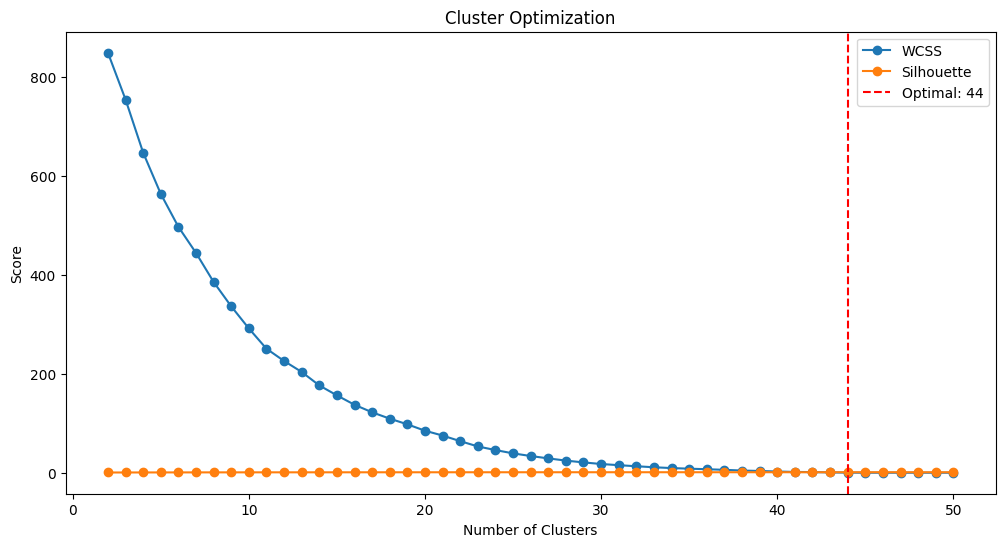

In [ ]:
# Visual Validation

plt.figure(figsize=(12, 6))
plt.plot(range(2, 51), wcss[:49], 'o-', label='WCSS')
plt.plot(range(2, 51), sil_scores[:49], 'o-', label='Silhouette')
plt.axvline(optimal_n, color='r', linestyle='--', label=f'Optimal: {optimal_n}')
plt.xlabel('Number of Clusters')
plt.ylabel('Score')
plt.legend()
plt.title('Cluster Optimization')
plt.show()

In [ ]:
# Final Clustering

kmeans = KMeans(n_clusters=optimal_n, random_state=42, n_init=20)
df['cluster'] = kmeans.fit_predict(embeddings)
df

,comments,cleaned_comments,translated_comments,standardized_comments,cluster
0,ras,rien à signaler,nothing to report,normal_consumption,4
1,produit en rupture cmm = 65,produit en rupture de stock cmm 65,product out of stock cmm 65,out_of_stock,3
2,cmm=50,cmm 50,cmm 50,real_cmm_adjustment,1
3,cmm=1,cmm 1,cmm 1,real_cmm_adjustment,1
4,cmm=21,cmm 21,cmm 21,real_cmm_adjustment,1
...,...,...,...,...,...
1915,consommation mensuelle est 100,consommation mensuelle est 100,monthly consumption is 100,real_cmm_adjustment,1
1916,ras / nous avons compté en unité mais pas en b...,rien à signaler / nous avons compté en unité m...,nothing to report / we counted in units but no...,cmm_reporting_in_packaging_units,7
1917,service ferme,service fermé,closed service,facility_issues,5
1918,activite arretee,activité arrêtée,activity stopped,immediate_breakup,10


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.11/dist-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


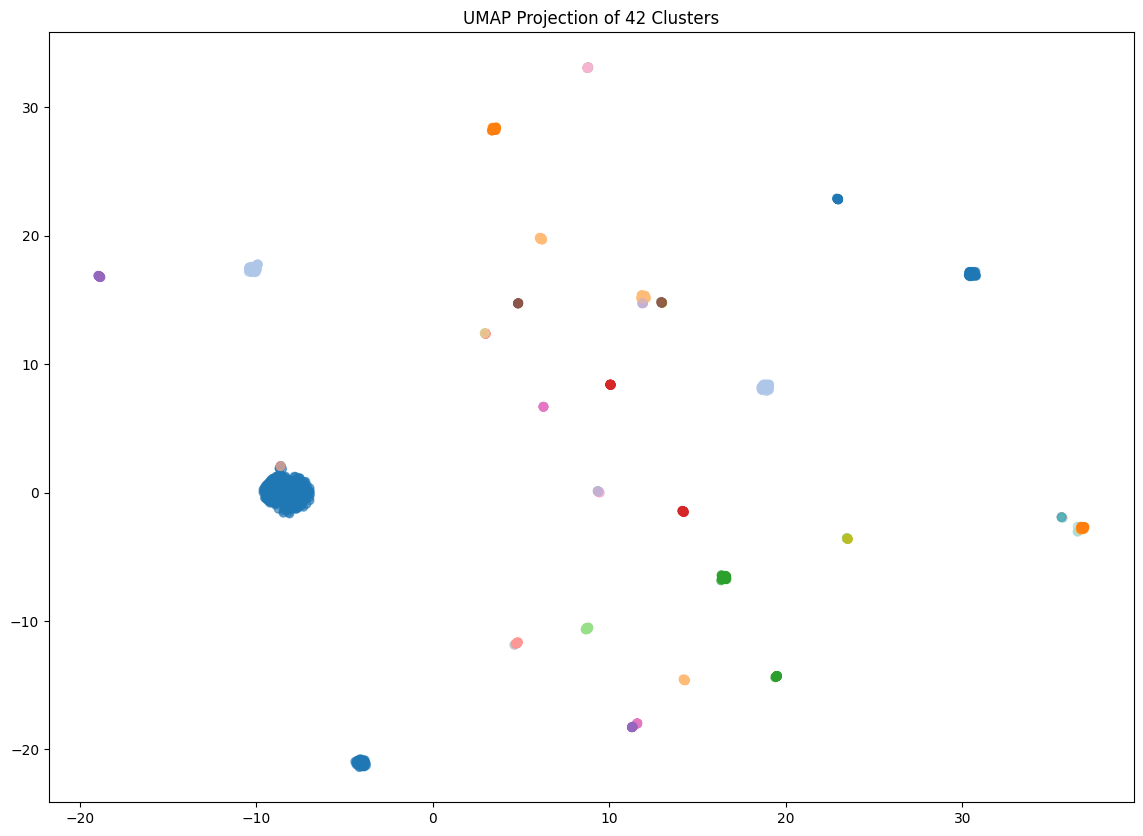

In [ ]:
# Visualize clusters

umap_embeds = UMAP(random_state=42).fit_transform(embeddings)
plt.figure(figsize=(14, 10))
plt.scatter(umap_embeds[:,0], umap_embeds[:,1], c=df['cluster'], cmap='tab20', alpha=0.6)
plt.title(f'UMAP Projection of {optimal_n} Clusters')
plt.show()

In [ ]:
# Print cluster samples

for cluster_id in sorted(df['cluster'].unique()):
    print(f"\nCluster {cluster_id} ({len(df[df['cluster']==cluster_id])} comments)")
    print("=" * 60)
    print(df[df['cluster']==cluster_id]['standardized_comments'].sample(5).to_string(index=False))

In [ ]:
# save files

df.to_csv('comments_cluster_df.csv', index = False)
files.download("comments_cluster_df.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>